# 🛠️ Project 42 — Synthetic Sensor Fault Diagnosis System
### Gaussian Naive Bayes for classifying machine health: **Normal · Warning · Critical**

**Category:** Naive Bayes Classifiers | **Table:** `machinery_vibration_telemetry`

| Section | What we do | Why it matters |
|---|---|---|
| 1 | Physics-inspired synthetic data → SQLite | Controlled, explainable ground truth |
| 2 | Gaussian NB **from scratch** (NumPy) vs scikit-learn | Proves we understand the maths |
| 3 | Correlation heatmaps | Tests the *"naive"* independence assumption |
| 4 | Calibration (Platt / Isotonic, Brier score) | Are the posterior probabilities trustworthy? |
| 5 | KDE likelihoods + log-likelihood contributions | Explains *why* the model decided what it decided |
| 6 | Pipeline, Stratified K-Fold, ROC-AUC, **cost-sensitive** evaluation | Catching Critical faults is what matters in industry |

> **Core idea in one line:** for every machine reading $\mathbf{x}$, compute $P(\text{state}\mid\mathbf{x})$ using Bayes' theorem, assuming sensors are independent *given the state*.

## 0. Setup & Imports
All randomness is controlled by one `SEED` so every run reproduces the exact same numbers (important for a report and viva!).

In [1]:
import sqlite3
import warnings
from contextlib import closing

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score, log_loss, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             recall_score, precision_score, make_scorer)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

SEED = 42

# ---- Domain constants used everywhere (keep class order FIXED: 0=Normal, 1=Warning, 2=Critical)
CLASSES      = ["Normal", "Warning", "Critical"]
CLASS_TO_INT = {c: i for i, c in enumerate(CLASSES)}
COLORS       = {"Normal": "#2a9d8f", "Warning": "#f4a261", "Critical": "#e63946"}
FEATURES     = ["vibration_amplitude_g", "acoustic_decibels",
                "bearing_temperature_c", "motor_amperage"]
SHORT        = ["Vibration", "Acoustic", "Temperature", "Amperage"]
UNITS        = ["g", "dB", "°C", "A"]
TABLE_NAME   = "machinery_vibration_telemetry"
DB_PATH      = "machinery_telemetry.db"
print("Setup complete ✔")

Setup complete ✔


---
## 1. Synthetic Data Generator (Physics-Inspired)

Real factories rarely give us labelled fault data, so we **simulate** it from simple physical reasoning.
Two hidden (latent) variables drive every sensor:

* $s \in [0,1]$ — **bearing wear severity** (higher = closer to failure). Its distribution depends on the true state.
* $L \in [0.5, 1]$ — **machine load factor** (how hard the machine is working).

| Sensor | Model | Physical reasoning |
|---|---|---|
| Vibration (g) | $0.6 + 4\,s^{2} + \varepsilon_v$ | Defect energy grows **non-linearly** with wear |
| Temperature (°C) | $40 + 22\,L + 38\,s + \varepsilon_T$ | Friction heat ∝ wear, plus heating from load |
| Acoustic (dB) | $60 + 6\,L + 12\,s + 1.5\,\text{vib} + \varepsilon_a$ | Broadband noise from load & wear, coupled to vibration |
| Amperage (A) | $10 + 16\,L + 5\,s + \varepsilon_I$ | Motor draws more current under load and extra friction torque |

with Gaussian noises $\varepsilon \sim \mathcal{N}(0,\sigma^2)$.

> ⚠️ **Key design choice:** $s$ and $L$ are **hidden** (not saved in the table). Because several sensors share them,
> the sensors stay **correlated even inside one class**. That *violates* Naive Bayes' independence assumption —
> deliberately — so Section 3 has something real to discuss.

In [2]:
def generate_machinery_telemetry(n_samples=6000,
                                 class_priors=(0.70, 0.20, 0.10),
                                 seed=SEED):
    """
    Simulate vibration / acoustic / temperature / current telemetry for rotating machinery.

    Returns a DataFrame with exactly the columns required by the project:
    machine_id, vibration_amplitude_g, acoustic_decibels,
    bearing_temperature_c, motor_amperage, operational_state
    """
    rng = np.random.default_rng(seed)

    # 1) Draw the TRUE operational state (imbalanced: most machines are healthy)
    states = rng.choice(CLASSES, size=n_samples, p=class_priors)

    # 2) Latent wear severity s: each state has its own (mean, std). Clipped to [0, 1].
    sev_params = {"Normal": (0.18, 0.10), "Warning": (0.48, 0.12), "Critical": (0.78, 0.12)}
    mu_s = np.array([sev_params[s][0] for s in states])
    sd_s = np.array([sev_params[s][1] for s in states])
    severity = np.clip(rng.normal(mu_s, sd_s), 0.0, 1.0)

    # 3) Latent load factor L (independent of health state)
    load = rng.uniform(0.5, 1.0, n_samples)

    # 4) Sensor physics + measurement noise
    vibration   = 0.6 + 4.0 * severity**2 + rng.normal(0, 0.30, n_samples)
    vibration   = np.clip(vibration, 0.05, None)                      # amplitude can't be negative
    temperature = 40 + 22 * load + 38 * severity + rng.normal(0, 3.5, n_samples)
    acoustic    = 60 + 6 * load + 12 * severity + 1.5 * vibration + rng.normal(0, 2.5, n_samples)
    amperage    = 10 + 16 * load + 5 * severity + rng.normal(0, 1.3, n_samples)

    return pd.DataFrame({
        "machine_id":            [f"MCH-{i:05d}" for i in range(1, n_samples + 1)],
        "vibration_amplitude_g": vibration.round(3),
        "acoustic_decibels":     acoustic.round(2),
        "bearing_temperature_c": temperature.round(2),
        "motor_amperage":        amperage.round(2),
        "operational_state":     states,
    })


def save_to_sqlite(df, db_path=DB_PATH, table=TABLE_NAME):
    """Persist the DataFrame as a proper SQL table (replaces it if it exists)."""
    with closing(sqlite3.connect(db_path)) as conn:
        df.to_sql(table, conn, if_exists="replace", index=False)


def query_sqlite(sql, db_path=DB_PATH):
    """Run any SQL query and return a DataFrame."""
    with closing(sqlite3.connect(db_path)) as conn:
        return pd.read_sql_query(sql, conn)


# ---- Generate -> Save -> Reload through SQL (end-to-end data engineering flow)
raw_df = generate_machinery_telemetry()
save_to_sqlite(raw_df)

print("Table schema:")
display(query_sqlite(f"PRAGMA table_info({TABLE_NAME});")[["name", "type"]])

print("\nSQL aggregate — class balance and average sensor readings:")
display(query_sqlite(f"""
    SELECT operational_state,
           COUNT(*)                          AS n_readings,
           ROUND(AVG(vibration_amplitude_g),2) AS avg_vib_g,
           ROUND(AVG(acoustic_decibels),1)     AS avg_db,
           ROUND(AVG(bearing_temperature_c),1) AS avg_temp_c,
           ROUND(AVG(motor_amperage),1)        AS avg_amps
    FROM {TABLE_NAME}
    GROUP BY operational_state
    ORDER BY avg_vib_g;
"""))

Table schema:


,name,type
0,machine_id,TEXT
1,vibration_amplitude_g,REAL
2,acoustic_decibels,REAL
3,bearing_temperature_c,REAL
4,motor_amperage,REAL
5,operational_state,TEXT



SQL aggregate — class balance and average sensor readings:


,operational_state,n_readings,avg_vib_g,avg_db,avg_temp_c,avg_amps
0,Normal,4245,0.78,67.8,63.4,22.9
1,Warning,1176,1.58,72.6,74.8,24.5
2,Critical,579,3.09,78.4,86.2,25.9


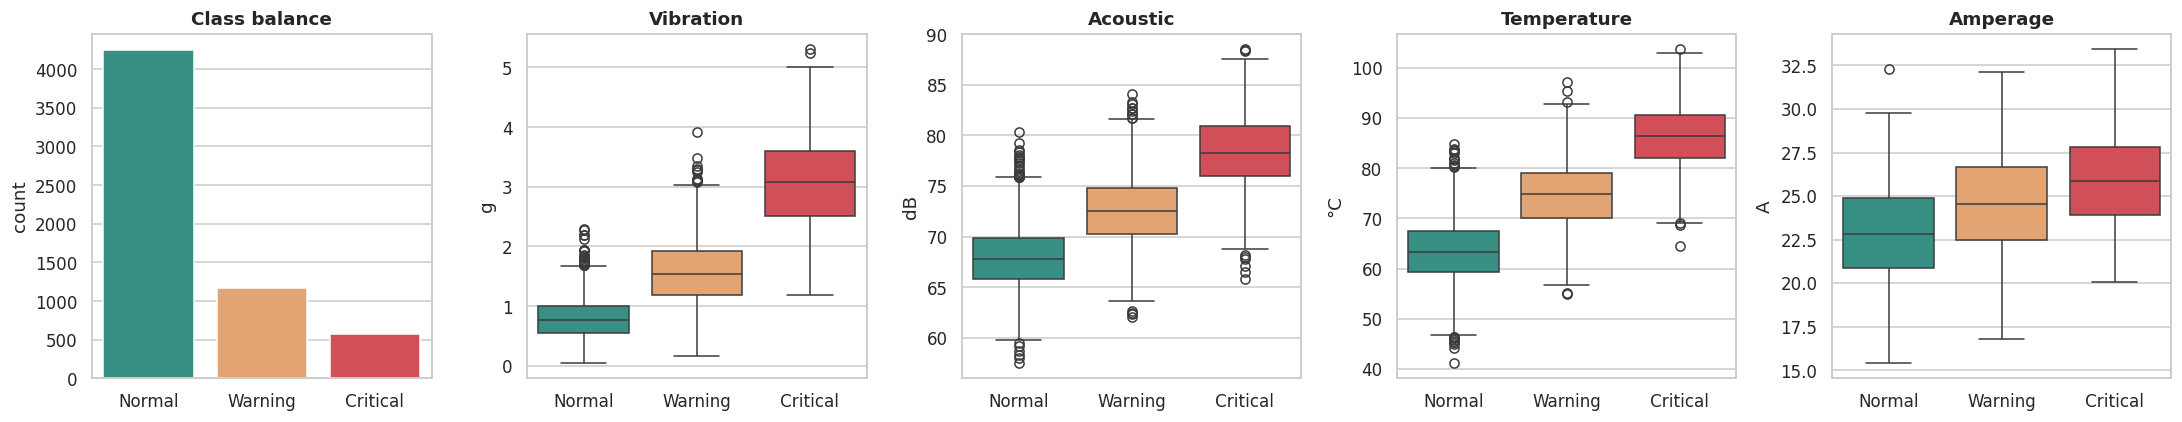

Train: (4500, 4)  |  Test: (1500, 4)
Train class proportions: [0.708 0.196 0.096]
Test  class proportions: [0.707 0.196 0.097]


In [3]:
# ---- Load the data back FROM the database (so the analysis uses the SQL table, not the in-memory frame)
df = query_sqlite(f"SELECT * FROM {TABLE_NAME};")
df["state_code"] = df["operational_state"].map(CLASS_TO_INT)

# ---- Quick EDA: class balance + one boxplot per sensor
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
sns.countplot(data=df, x="operational_state", hue="operational_state", order=CLASSES, hue_order=CLASSES, palette=COLORS, legend=False, ax=axes[0])
axes[0].set_title("Class balance"); axes[0].set_xlabel("")
for ax, feat, short, unit in zip(axes[1:], FEATURES, SHORT, UNITS):
    sns.boxplot(data=df, x="operational_state", y=feat, hue="operational_state", order=CLASSES, hue_order=CLASSES, palette=COLORS, dodge=False, legend=False, ax=ax)
    ax.set_title(short); ax.set_xlabel(""); ax.set_ylabel(unit)
plt.tight_layout(); plt.show()

# ---- Stratified train / test split (keeps the 70/20/10 ratio in both halves)
X = df[FEATURES].to_numpy()
y = df["state_code"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print("Train class proportions:", np.round(np.bincount(y_train) / len(y_train), 3))
print("Test  class proportions:", np.round(np.bincount(y_test)  / len(y_test), 3))

---
## 2. Maths from Scratch — Gaussian Naive Bayes in Pure NumPy

### 2.1 Bayes' theorem for classification
For a reading $\mathbf{x}=(x_1,\dots,x_d)$ and class $c$:

$$P(c\mid\mathbf{x})=\frac{P(c)\,P(\mathbf{x}\mid c)}{P(\mathbf{x})}$$

* $P(c)$ — **prior**: how common is this state? (e.g. 70 % Normal)
* $P(\mathbf{x}\mid c)$ — **likelihood**: how typical is this reading *for that state*?
* $P(\mathbf{x})$ — **evidence**: a normaliser so that probabilities sum to 1.

### 2.2 The "naive" step
Modelling the full joint $P(x_1,\dots,x_d\mid c)$ needs a full covariance matrix per class. Naive Bayes assumes the features are **conditionally independent given the class**:

$$P(\mathbf{x}\mid c)=\prod_{j=1}^{d}P(x_j\mid c)$$

and the "Gaussian" part says each factor is a normal density:

$$P(x_j\mid c)=\frac{1}{\sqrt{2\pi\sigma_{jc}^{2}}}\exp\!\left(-\frac{(x_j-\mu_{jc})^{2}}{2\sigma_{jc}^{2}}\right)$$

### 2.3 Training = Maximum Likelihood Estimation (MLE)
For the $n_c$ training samples of class $c$, the log-likelihood of feature $j$ is

$$\ell(\mu,\sigma^{2})=-\frac{n_c}{2}\ln(2\pi\sigma^{2})-\frac{1}{2\sigma^{2}}\sum_{i=1}^{n_c}(x_i-\mu)^{2}$$

Setting the derivatives to zero:

$$\frac{\partial \ell}{\partial \mu}=0\;\Rightarrow\;\hat\mu_{jc}=\frac{1}{n_c}\sum_i x_{ij},\qquad
\frac{\partial \ell}{\partial \sigma^{2}}=0\;\Rightarrow\;\hat\sigma^{2}_{jc}=\frac{1}{n_c}\sum_i (x_{ij}-\hat\mu_{jc})^{2}$$

Note the divisor is $n_c$ (**biased MLE**, `ddof=0`), not $n_c-1$. The prior is just the class frequency: $\hat\pi_c=n_c/n$.
**There is no gradient descent — "training" is a single pass computing means, variances and counts.** That is why NB is so fast.

### 2.4 Prediction in log-space
Multiplying many small densities underflows to `0.0`, so we work with **logs**:

$$\log P(c\mid\mathbf{x}) = \underbrace{\log\pi_c-\tfrac12\sum_j\Big[\log(2\pi\sigma_{jc}^{2})+\tfrac{(x_j-\mu_{jc})^{2}}{\sigma_{jc}^{2}}\Big]}_{\text{joint log-score } a_c}\;-\;\log\sum_k e^{a_k}$$

### 2.5 The log-sum-exp trick
To get the normaliser safely, subtract the maximum $m=\max_k a_k$ first:

$$\log\sum_k e^{a_k}=m+\log\sum_k e^{a_k-m}$$

The largest term becomes $e^{0}=1$, so nothing underflows.

### 2.6 Variance smoothing
If a feature has (almost) zero variance in a class, the density explodes. Scikit-learn adds $\epsilon = 10^{-9}\cdot\max_j \mathrm{Var}(x_j)$ to every variance. We replicate it exactly.

In [4]:
def logsumexp(a, axis=1):
    """Numerically stable log(sum(exp(a))) — subtract the max before exponentiating."""
    m = np.max(a, axis=axis, keepdims=True)                       # m = max_k a_k
    return m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))


class GaussianNBScratch:
    """Gaussian Naive Bayes implemented with NumPy only (mirrors sklearn's API)."""

    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    # ---------------- TRAINING (MLE) ----------------
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_ = np.unique(y)
        K, d = len(self.classes_), X.shape[1]
        self.theta_       = np.zeros((K, d))      # means  mu_{jc}
        self.var_         = np.zeros((K, d))      # variances sigma^2_{jc}
        self.class_prior_ = np.zeros(K)           # priors pi_c

        # sklearn's smoothing term: 1e-9 * largest feature variance over the WHOLE training set
        self.epsilon_ = self.var_smoothing * np.var(X, axis=0).max()

        for i, c in enumerate(self.classes_):
            Xc = X[y == c]
            self.theta_[i]       = Xc.mean(axis=0)
            self.var_[i]         = Xc.var(axis=0)          # ddof=0  ->  MLE
            self.class_prior_[i] = Xc.shape[0] / X.shape[0]
        self.var_ += self.epsilon_
        return self

    # ---------------- INFERENCE ----------------
    def _log_joint(self, X):
        """Returns (joint log-score a_c of shape (n,K), per-feature log-likelihoods of shape (n,K,d))."""
        X = np.asarray(X, dtype=float)
        diff = X[:, None, :] - self.theta_[None, :, :]                     # (n, K, d)
        ll_feat = (-0.5 * np.log(2 * np.pi * self.var_)[None, :, :]
                   - 0.5 * diff**2 / self.var_[None, :, :])                # log N(x_j | mu, var)
        joint = np.log(self.class_prior_)[None, :] + ll_feat.sum(axis=2)   # log-prior + sum of logs
        return joint, ll_feat

    def predict_log_proba(self, X):
        joint, _ = self._log_joint(X)
        return joint - logsumexp(joint, axis=1)          # normalise in log-space

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        joint, _ = self._log_joint(X)
        return self.classes_[np.argmax(joint, axis=1)]   # argmax of log-posterior (evidence cancels)


# ---- Fit both models on the SAME training data
scratch = GaussianNBScratch().fit(X_train, y_train)
sk_gnb  = GaussianNB().fit(X_train, y_train)

# ---- 1) Learned parameters must match
print("Means match      :", np.allclose(scratch.theta_, sk_gnb.theta_))
print("Variances match  :", np.allclose(scratch.var_, sk_gnb.var_))
print("Priors match     :", np.allclose(scratch.class_prior_, sk_gnb.class_prior_))

# ---- 2) Predictions and probabilities must match
pred_scratch, pred_sk = scratch.predict(X_test), sk_gnb.predict(X_test)
proba_scratch, proba_sk = scratch.predict_proba(X_test), sk_gnb.predict_proba(X_test)
print("\nIdentical predictions on test set:", np.array_equal(pred_scratch, pred_sk))
print("Max |difference| in probabilities :", f"{np.abs(proba_scratch - proba_sk).max():.2e}")
print(f"Test accuracy (scratch) = {accuracy_score(y_test, pred_scratch):.4f} | "
      f"(sklearn) = {accuracy_score(y_test, pred_sk):.4f}")

# ---- 3) Learned parameters as a readable table
params = pd.concat({CLASSES[i]: pd.DataFrame({"mean": scratch.theta_[i],
                                              "std": np.sqrt(scratch.var_[i])}, index=SHORT)
                    for i in range(3)}, axis=1).round(3)
print("\nLearned Gaussian parameters (what the model 'knows'):")
display(params)
print("Learned priors:", dict(zip(CLASSES, scratch.class_prior_.round(3))))

Means match      : True
Variances match  : True
Priors match     : True

Identical predictions on test set: True
Max |difference| in probabilities : 1.89e-15
Test accuracy (scratch) = 0.8727 | (sklearn) = 0.8727

Learned Gaussian parameters (what the model 'knows'):


Normal        Warning        Critical       
               mean    std    mean    std     mean    std
Vibration     0.779  0.337   1.572  0.564    3.110  0.763
Acoustic     67.846  3.014  72.624  3.589   78.472  3.607
Temperature  63.549  6.061  74.735  6.621   86.372  6.230
Amperage     22.878  2.714  24.456  2.706   25.966  2.687

Learned priors: {'Normal': np.float64(0.708), 'Warning': np.float64(0.196), 'Critical': np.float64(0.096)}


### 2.7 Why log-space & log-sum-exp matter — a live demonstration

In [5]:
rng = np.random.default_rng(0)

# (a) Multiplying many densities underflows to exactly 0.0; summing logs does not.
x = rng.normal(size=1000)                       # imagine 1000 features
pdfs = stats.norm.pdf(x)
print("Product of 1000 densities      :", np.prod(pdfs), " <- underflow!")
print("Sum of 1000 log-densities      :", np.sum(np.log(pdfs)).round(2), " <- perfectly fine")

# (b) Naive normalisation of very negative log-scores gives 0/0 = NaN; log-sum-exp is stable.
a = np.array([[-1050.0, -1052.0, -1060.0]])     # joint log-scores a_c
naive = np.exp(a) / np.exp(a).sum()
stable = np.exp(a - logsumexp(a))
print("\nNaive softmax                  :", naive)
print("Log-sum-exp softmax            :", stable.round(4))

Product of 1000 densities      : 0.0  <- underflow!
Sum of 1000 log-densities      : -1397.12  <- perfectly fine

Naive softmax                  : [[nan nan nan]]
Log-sum-exp softmax            : [[0.8808 0.1192 0.    ]]


---
## 3. Testing the "Naive" Assumption

Naive Bayes needs **conditional independence given the class**:
$$P(x_i,x_j\mid c)=P(x_i\mid c)\,P(x_j\mid c)$$
If true, the **within-class** correlation between any two sensors should be ≈ 0.

We plot:
1. The **pooled** correlation (all classes mixed). It is *expected* to be high, because the class itself drives every sensor — this is **not** a violation.
2. The **within-class** correlation. *This* is what the assumption is about.

Then we ask the key question: **does breaking the assumption actually hurt accuracy?**
We compare Naive Bayes (diagonal covariance) with **QDA** (a Gaussian model with *full* covariance per class, no independence assumption).

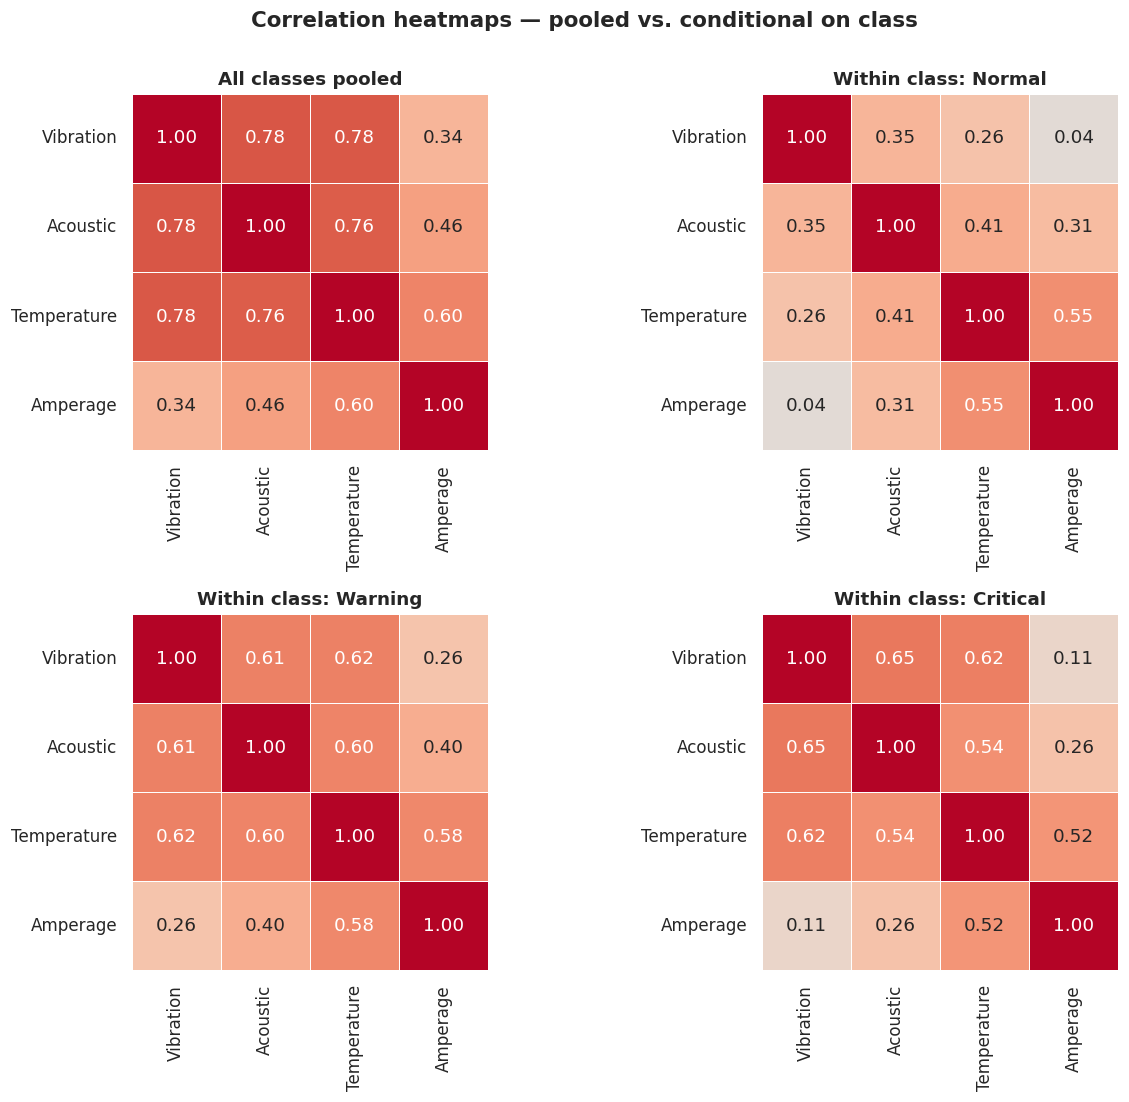

Mean |off-diagonal correlation| (0 = perfectly 'naive'):


,mean |corr|
All classes pooled,0.622
Within class: Normal,0.320
Within class: Warning,0.509
Within class: Critical,0.451


In [6]:
train_df = pd.DataFrame(X_train, columns=FEATURES)
train_df["state"] = y_train

panels = [("All classes pooled", train_df)] + \
         [(f"Within class: {c}", train_df[train_df["state"] == i]) for i, c in enumerate(CLASSES)]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (title, d) in zip(axes.ravel(), panels):
    corr = d[FEATURES].corr()
    corr.index = corr.columns = SHORT
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                square=True, cbar=False, linewidths=0.5, ax=ax)
    ax.set_title(title)
plt.suptitle("Correlation heatmaps — pooled vs. conditional on class", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

# ---- One-number summary: mean absolute off-diagonal correlation
def mean_abs_offdiag(corr):
    m = corr.to_numpy()
    return np.abs(m[~np.eye(len(m), dtype=bool)]).mean()

summary = {title: mean_abs_offdiag(d[FEATURES].corr()) for title, d in panels}
print("Mean |off-diagonal correlation| (0 = perfectly 'naive'):")
display(pd.Series(summary, name="mean |corr|").round(3).to_frame())

In [7]:
# ---- Does the violated assumption hurt? Naive Bayes vs QDA (full covariance, no independence assumption)
gnb_cmp = GaussianNB().fit(X_train, y_train)
qda_cmp = QuadraticDiscriminantAnalysis().fit(X_train, y_train)

rows = []
for name, mdl in [("Gaussian NB (independent)", gnb_cmp), ("QDA (full covariance)", qda_cmp)]:
    P = mdl.predict_proba(X_test)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, mdl.predict(X_test)),
                 "log-loss": log_loss(y_test, P),
                 "Critical recall": recall_score(y_test, mdl.predict(X_test), labels=[2], average="macro")})
display(pd.DataFrame(rows).set_index("model").round(4))

,accuracy,log-loss,Critical recall
model,,,
Gaussian NB (independent),0.8727,0.4220,0.7793
QDA (full covariance),0.8867,0.2957,0.7379


### 📌 How to interpret (talking points for the viva)
* **Pooled** correlations are high because Normal → Warning → Critical lifts *all* sensors together. That is exactly the **signal** NB uses — not a flaw.
* **Within-class** correlations are smaller but *not zero*: the hidden load factor $L$ (and wear severity $s$) move temperature, amperage and acoustic noise together. The naive assumption is therefore **violated**.
* **Consequence:** NB multiplies correlated evidence as if it were independent → it **double-counts** evidence → posteriors become **over-confident** (too close to 0 or 1). Classification (the argmax) is usually robust, but *probabilities* are not. This motivates **Section 4 (calibration)**.
* QDA models correlations explicitly, so comparing it with NB quantifies how much the violation really costs.

---
## 4. Calibration — Can We Trust the Probabilities?

A model is **calibrated** if, among all readings where it says "80 % Critical", about 80 % really are Critical.

| Metric | Formula | Meaning |
|---|---|---|
| **Brier score** (multi-class) | $\displaystyle \frac1N\sum_{i}\sum_{k}\big(p_{ik}-y_{ik}\big)^2$ | Mean squared error of the probabilities. **Lower is better** (0 = perfect) |
| **Log-loss** | $-\frac1N\sum_i\log p_{i,y_i}$ | Heavily punishes confident mistakes |
| **ECE** | $\sum_b \frac{n_b}{N}\,\big\lvert \text{acc}_b-\text{conf}_b\big\rvert$ | Average gap between confidence and accuracy over bins |

**Reliability diagram:** bin predicted probabilities (x-axis) and plot the *observed* frequency (y-axis). The diagonal is perfect calibration; a curve **below** it means over-confidence.

**Two post-hoc fixes** (both learn a map from raw scores to calibrated probabilities using cross-validation):
* **Platt scaling (`sigmoid`)**: $p_{\text{cal}}=\dfrac{1}{1+e^{-(A f+B)}}$ — a 2-parameter S-curve; for multi-class it is applied one-vs-rest and renormalised.
* **Isotonic regression**: fits a free-form **monotone non-decreasing** step function (Pool-Adjacent-Violators). More flexible, but needs more data.

,accuracy,Brier (3-class),Brier (Critical),log-loss,ECE
model,,,,,
Uncalibrated GNB,0.8727,0.2074,0.0333,0.4220,0.0687
Platt (sigmoid),0.8753,0.2012,0.0333,0.3861,0.0459
Isotonic,0.8753,0.1895,0.0304,0.3705,0.0039


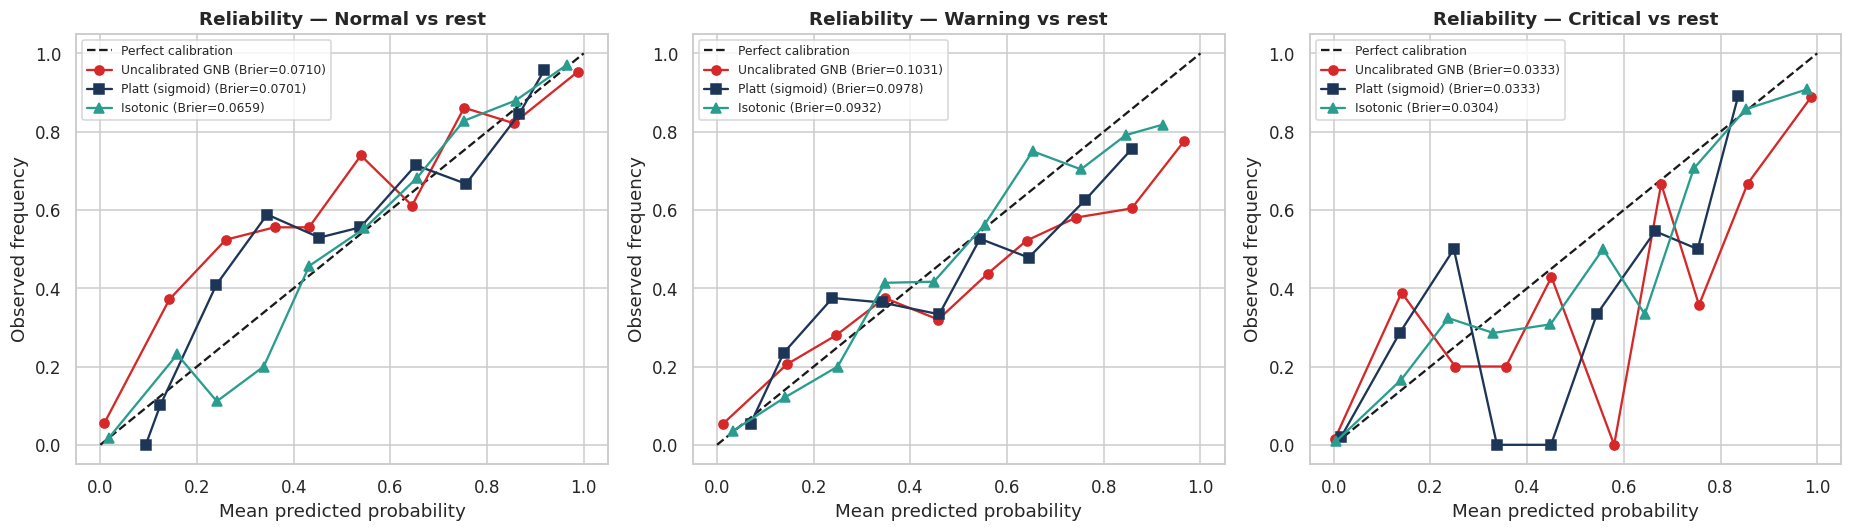

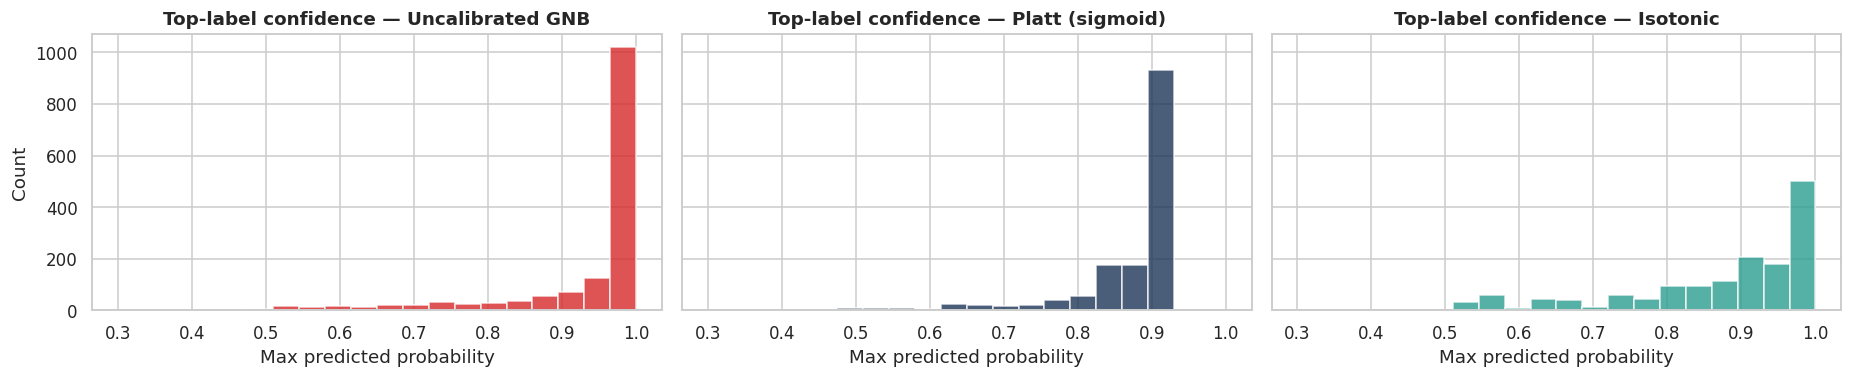

In [8]:
def multiclass_brier(P, y_true, n_classes=3):
    Y = np.eye(n_classes)[y_true]                       # one-hot encode labels
    return np.mean(np.sum((P - Y) ** 2, axis=1))

def expected_calibration_error(P, y_true, n_bins=10):
    conf, pred = P.max(axis=1), P.argmax(axis=1)        # top-label confidence
    correct = (pred == y_true)
    edges, ece = np.linspace(0, 1, n_bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return ece

# ---- Three competing models (calibrators use 5-fold CV INSIDE the training set -> no test leakage)
models = {
    "Uncalibrated GNB":    GaussianNB().fit(X_train, y_train),
    "Platt (sigmoid)":     CalibratedClassifierCV(GaussianNB(), method="sigmoid",  cv=5).fit(X_train, y_train),
    "Isotonic":            CalibratedClassifierCV(GaussianNB(), method="isotonic", cv=5).fit(X_train, y_train),
}
probs = {name: m.predict_proba(X_test) for name, m in models.items()}

rows = []
for name, P in probs.items():
    rows.append({"model": name,
                 "accuracy":        accuracy_score(y_test, P.argmax(1)),
                 "Brier (3-class)": multiclass_brier(P, y_test),
                 "Brier (Critical)": brier_score_loss(y_test == 2, P[:, 2]),
                 "log-loss":        log_loss(y_test, P),
                 "ECE":             expected_calibration_error(P, y_test)})
calib_table = pd.DataFrame(rows).set_index("model")
display(calib_table.round(4))

# ---- Reliability diagrams (one-vs-rest, one panel per class)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
line_style = {"Uncalibrated GNB": ("o-", "#d62828"), "Platt (sigmoid)": ("s-", "#1d3557"), "Isotonic": ("^-", "#2a9d8f")}
for k, (ax, cls) in enumerate(zip(axes, CLASSES)):
    ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
    for name, P in probs.items():
        frac_pos, mean_pred = calibration_curve(y_test == k, P[:, k], n_bins=10, strategy="uniform")
        fmt, col = line_style[name]
        b = brier_score_loss(y_test == k, P[:, k])
        ax.plot(mean_pred, frac_pos, fmt, color=col, label=f"{name} (Brier={b:.4f})")
    ax.set_title(f"Reliability — {cls} vs rest")
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed frequency")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

# ---- Confidence histogram: NB's over-confidence is visible as a pile-up at 0 and 1
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), sharey=True)
for ax, (name, P) in zip(axes, probs.items()):
    ax.hist(P.max(axis=1), bins=20, range=(0.3, 1), color=line_style[name][1], alpha=0.8)
    ax.set_title(f"Top-label confidence — {name}"); ax.set_xlabel("Max predicted probability")
axes[0].set_ylabel("Count")
plt.tight_layout(); plt.show()

### 📌 How to interpret
* **Uncalibrated NB** pushes most probabilities to the extremes (see histogram). Because correlated sensors are double-counted, it is **over-confident**: in our run its average confidence is ≈ 0.94 while its accuracy is ≈ 0.87, and over half of all predictions carry > 99 % confidence. In the reliability curves the high-probability bins sit **below** the diagonal (note: bins with few samples are noisy, especially for the rare Critical class).
* **Platt / Isotonic** pull the curve towards the diagonal, so **Brier score and ECE drop** while accuracy stays about the same.
* **Moral:** *accuracy* and *probability quality* are different things. For maintenance decisions ("shut down if $P(\text{Critical})>0.3$") we need **trustworthy probabilities**, not just correct labels.

---
## 5. Visualising the Likelihoods — *Why* did the model decide that?

### 5.1 Class-conditional distributions
For each sensor we draw the **empirical KDE** (solid, data-driven) and the **Gaussian fitted by NB** (dashed, $\mathcal{N}(\hat\mu_{jc},\hat\sigma_{jc}^2)$).
The closer the dashed curve hugs the solid one, the better the Gaussian assumption holds. Where the classes separate, the sensor is **informative**.

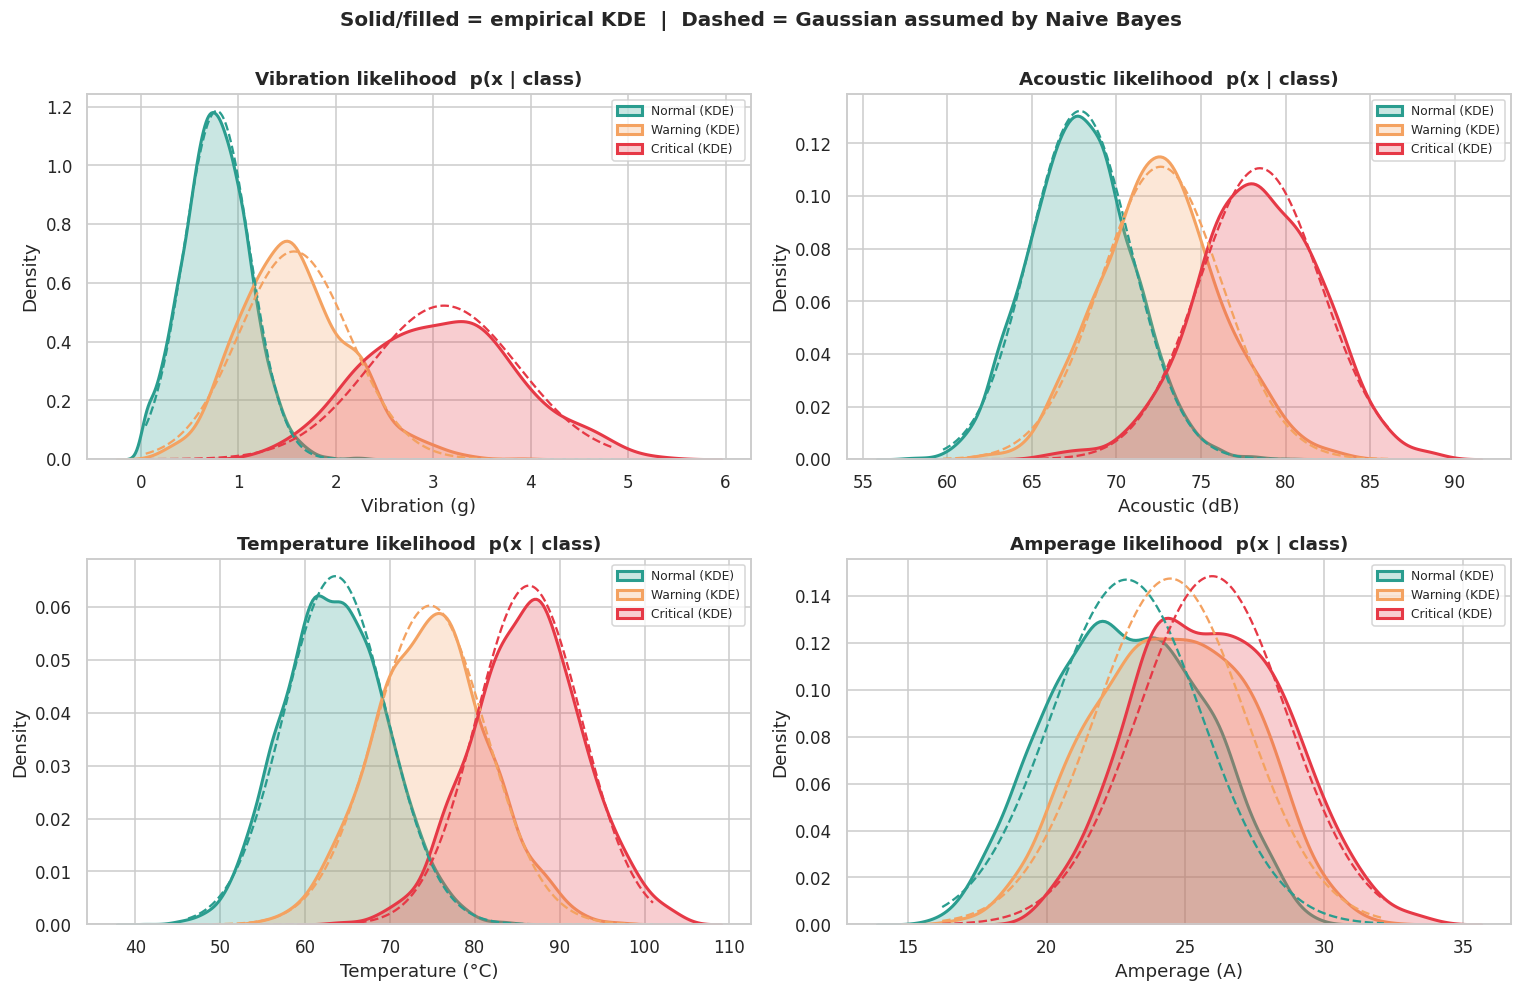

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for j, (ax, feat, short, unit) in enumerate(zip(axes.ravel(), FEATURES, SHORT, UNITS)):
    lo, hi = df[feat].quantile([0.001, 0.999])
    grid = np.linspace(lo, hi, 400)
    for i, cls in enumerate(CLASSES):
        data = df.loc[df["state_code"] == i, feat]
        sns.kdeplot(data, ax=ax, color=COLORS[cls], fill=True, alpha=0.25, linewidth=2, label=f"{cls} (KDE)")
        # Gaussian actually used by the model (from the scratch fit)
        ax.plot(grid, stats.norm.pdf(grid, scratch.theta_[i, j], np.sqrt(scratch.var_[i, j])),
                "--", color=COLORS[cls], linewidth=1.5)
    ax.set_title(f"{short} likelihood  p(x | class)")
    ax.set_xlabel(f"{short} ({unit})"); ax.set_ylabel("Density")
    ax.legend(fontsize=8)
plt.suptitle("Solid/filled = empirical KDE  |  Dashed = Gaussian assumed by Naive Bayes",
             fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

### 5.2 Explaining a single prediction — log-likelihood contributions

Because NB is a *sum of log terms*, its decision is **fully decomposable**. For two classes $A$ (e.g. Critical) and $B$ (e.g. Normal):

$$\underbrace{\log\frac{P(A\mid\mathbf{x})}{P(B\mid\mathbf{x})}}_{\text{posterior log-odds}}=\underbrace{\log\frac{\pi_A}{\pi_B}}_{\text{prior}}+\sum_{j=1}^{d}\underbrace{\log\frac{p(x_j\mid A)}{p(x_j\mid B)}}_{\text{evidence from sensor } j}$$

* A **positive** bar means that sensor *votes for* class $A$; **negative** means it votes for $B$.
* The bars add up (waterfall) to the final log-odds — the model's complete "reasoning".
* The **prior** bar is negative for Critical-vs-Normal because Critical machines are rare (10 % vs 70 %).

Machine #11: true state = Critical | predicted = Warning
Sensor readings : {'Vibration': np.float64(2.96), 'Acoustic': np.float64(74.59), 'Temperature': np.float64(76.76), 'Amperage': np.float64(22.3)}
Posterior       : {'Normal': np.float64(0.0), 'Warning': np.float64(0.5367), 'Critical': np.float64(0.4633)}


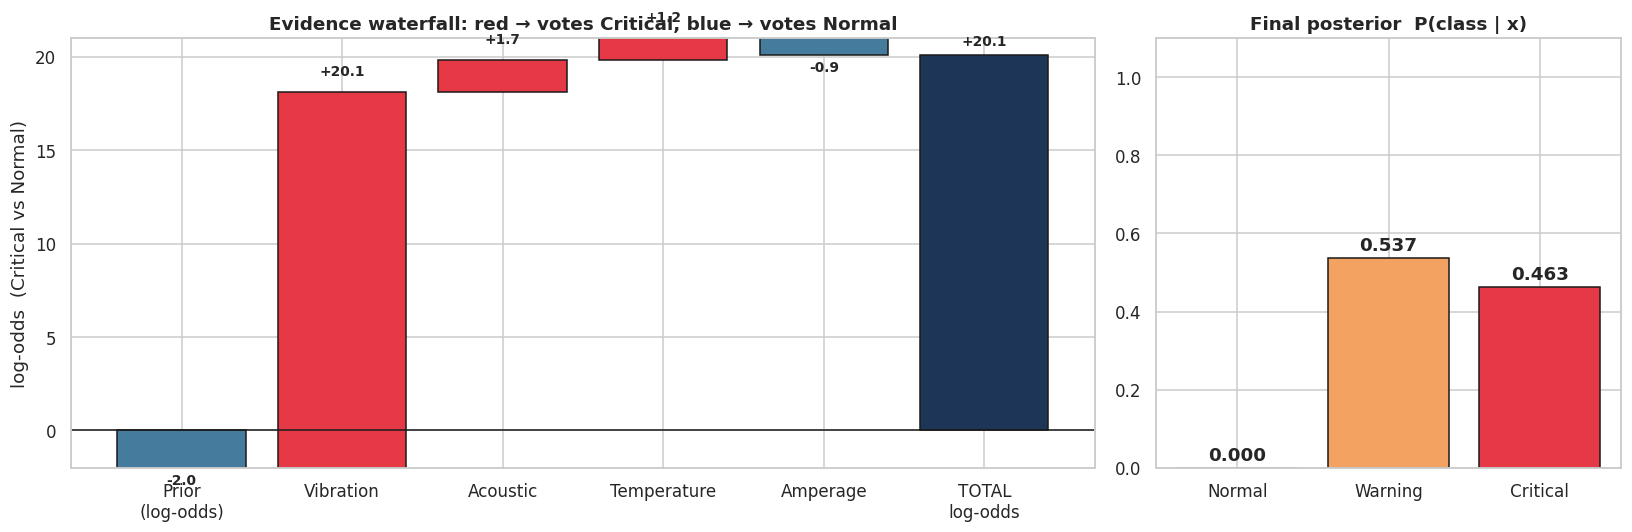


log p(x_j | class) for this machine (higher = more typical for that class):


,Vibration,Acoustic,Temperature,Amperage,log-prior,log-joint
Normal,-20.75,-4.53,-5.10,-1.94,-0.35,-32.66
Warning,-3.35,-2.35,-2.86,-2.23,-1.63,-12.42
Critical,-0.67,-2.78,-3.94,-2.84,-2.34,-12.57


In [10]:
# ---- Pick ONE test machine to explain (change `idx` to inspect others; here: first truly-Critical machine)
idx = int(np.where(y_test == 2)[0][0])
x_one = X_test[idx:idx + 1]
true_state = CLASSES[y_test[idx]]

_, ll_feat = scratch._log_joint(x_one)
ll_feat = ll_feat[0]                                            # shape (K, d)
post = scratch.predict_proba(x_one)[0]
print(f"Machine #{idx}: true state = {true_state} | predicted = {CLASSES[post.argmax()]}")
print("Sensor readings :", dict(zip(SHORT, x_one[0].round(2))))
print("Posterior       :", dict(zip(CLASSES, post.round(4))))

target, rival = 2, 0                                            # Critical vs Normal
prior_lo = np.log(scratch.class_prior_[target] / scratch.class_prior_[rival])
llr = ll_feat[target] - ll_feat[rival]                          # per-sensor evidence (log-likelihood ratio)
steps = [("Prior\n(log-odds)", prior_lo)] + list(zip(SHORT, llr))
total = sum(v for _, v in steps)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.2, 1]})

# (left) waterfall of evidence
ax = axes[0]
cum = 0.0
for k, (name, val) in enumerate(steps):
    ax.bar(k, val, bottom=cum, color="#e63946" if val > 0 else "#457b9d", edgecolor="k")
    ax.text(k, cum + val + (0.02 * abs(total) + 0.5) * np.sign(val if val != 0 else 1),
            f"{val:+.1f}", ha="center", fontsize=9, fontweight="bold")
    cum += val
ax.bar(len(steps), total, color="#1d3557", edgecolor="k")
ax.text(len(steps), total + 0.5 * np.sign(total), f"{total:+.1f}", ha="center", fontsize=9, fontweight="bold")
ax.axhline(0, color="k", linewidth=1)
ax.set_xticks(range(len(steps) + 1))
ax.set_xticklabels([n for n, _ in steps] + ["TOTAL\nlog-odds"])
ax.set_ylabel("log-odds  (Critical vs Normal)")
ax.set_title("Evidence waterfall: red → votes Critical, blue → votes Normal")

# (right) final posterior
ax = axes[1]
ax.bar(CLASSES, post, color=[COLORS[c] for c in CLASSES], edgecolor="k")
for i, p in enumerate(post):
    ax.text(i, p + 0.02, f"{p:.3f}", ha="center", fontweight="bold")
ax.set_ylim(0, 1.1); ax.set_title("Final posterior  P(class | x)")
plt.tight_layout(); plt.show()

# ---- Full per-class, per-sensor log-likelihood table
ll_table = pd.DataFrame(ll_feat, index=CLASSES, columns=SHORT).round(2)
ll_table["log-prior"] = np.log(scratch.class_prior_).round(2)
ll_table["log-joint"] = (ll_feat.sum(axis=1) + np.log(scratch.class_prior_)).round(2)
print("\nlog p(x_j | class) for this machine (higher = more typical for that class):")
display(ll_table)

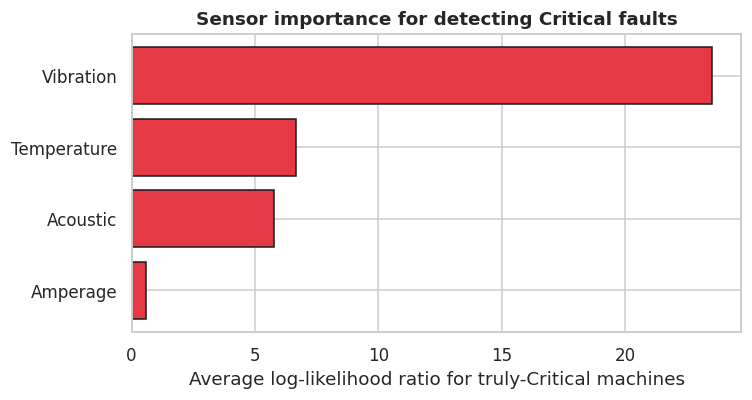

In [11]:
# ---- Global view: which sensors carry the most Critical-vs-Normal evidence across ALL test machines?
_, ll_all = scratch._log_joint(X_test)                           # (n, K, d)
llr_all = ll_all[:, 2, :] - ll_all[:, 0, :]                      # (n, d)  Critical-vs-Normal evidence
mask = y_test == 2                                               # only look at truly Critical machines
importance = pd.DataFrame({"sensor": SHORT,
                           "mean evidence (log-odds)": llr_all[mask].mean(axis=0)}).sort_values(
                           "mean evidence (log-odds)", ascending=True)

plt.figure(figsize=(7, 3.8))
plt.barh(importance["sensor"], importance["mean evidence (log-odds)"], color="#e63946", edgecolor="k")
plt.xlabel("Average log-likelihood ratio for truly-Critical machines")
plt.title("Sensor importance for detecting Critical faults")
plt.tight_layout(); plt.show()

### 📌 How to interpret
* A sensor with **well-separated** class curves (Section 5.1) delivers a **large** log-likelihood ratio — it is a strong witness. Overlapping curves give ratios near 0 — weak witness.
* Naive Bayes is a **glass box**: unlike a neural network, we can print exactly how many "log-odds points" each sensor contributed to a decision. Plant engineers can audit it.
* This is also where the naive assumption shows up: if two sensors carry the *same* information (e.g. vibration & acoustic), their bars both count in full → double-counting.

---
## 6. Production Pipeline, Stratified K-Fold & Cost-Sensitive Evaluation

### 6.1 Pipeline
`Pipeline([StandardScaler → GaussianNB])` guarantees that the scaler is **fitted only on the training fold** inside every CV split → **no data leakage**.

> 💡 **Interesting fact:** Gaussian NB is **scale-invariant** — standardising shifts each mean and rescales each variance by exactly the same factor as the data, so the posteriors are unchanged. We keep the scaler because the project requires it, it is good practice when the model is later swapped (KNN, logistic regression…), and we **prove** the invariance below.

### 6.2 Stratified K-Fold
Each of the $K=5$ folds keeps the 70/20/10 class ratio, so the rare **Critical** class appears in every fold.

### 6.3 Metrics
* **ROC-AUC (one-vs-rest, macro)** — ranking quality of the probabilities, independent of any threshold.
* **Critical recall** $=\dfrac{TP_{\text{Crit}}}{TP_{\text{Crit}}+FN_{\text{Crit}}}$ — *of all real critical faults, how many did we catch?* A missed Critical fault can mean a destroyed machine.

In [12]:
pipe = Pipeline([("scaler", StandardScaler()),
                 ("gnb",    GaussianNB())])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scoring = {
    "accuracy":          "accuracy",
    "macro_f1":          "f1_macro",
    "roc_auc_ovr":       "roc_auc_ovr",
    "critical_recall":   make_scorer(recall_score,    labels=[2], average="macro"),
    "critical_precision": make_scorer(precision_score, labels=[2], average="macro", zero_division=0),
}
cv_res = cross_validate(pipe, X, y, cv=skf, scoring=scoring)

cv_table = pd.DataFrame({m: cv_res[f"test_{m}"] for m in scoring},
                        index=[f"Fold {i+1}" for i in range(5)])
cv_table.loc["MEAN"] = cv_table.mean()
cv_table.loc["STD"]  = cv_table.iloc[:5].std()
print("5-fold Stratified Cross-Validation results:")
display(cv_table.round(4))

# ---- Proof of scale invariance: scaled pipeline vs raw GaussianNB make the same predictions
raw_pred = GaussianNB().fit(X_train, y_train).predict(X_test)
pipe_pred = pipe.fit(X_train, y_train).predict(X_test)
print(f"\nPredictions identical with / without StandardScaler: {np.mean(raw_pred == pipe_pred)*100:.2f}% agreement")

5-fold Stratified Cross-Validation results:


,accuracy,macro_f1,roc_auc_ovr,critical_recall,critical_precision
Fold 1,0.8625,0.7927,0.9410,0.7913,0.7982
Fold 2,0.8775,0.8143,0.9526,0.8966,0.7647
Fold 3,0.8558,0.7895,0.9314,0.8017,0.8304
Fold 4,0.8708,0.7931,0.9393,0.8103,0.7581
Fold 5,0.8533,0.7745,0.9290,0.8276,0.7619
MEAN,0.8640,0.7928,0.9387,0.8255,0.7827
STD,0.0101,0.0142,0.0093,0.0419,0.0311



Predictions identical with / without StandardScaler: 100.00% agreement


              precision    recall  f1-score   support

      Normal      0.928     0.935     0.932      4245
     Warning      0.662     0.628     0.645      1176
    Critical      0.781     0.826     0.803       579

    accuracy                          0.864      6000
   macro avg      0.791     0.796     0.793      6000
weighted avg      0.862     0.864     0.863      6000



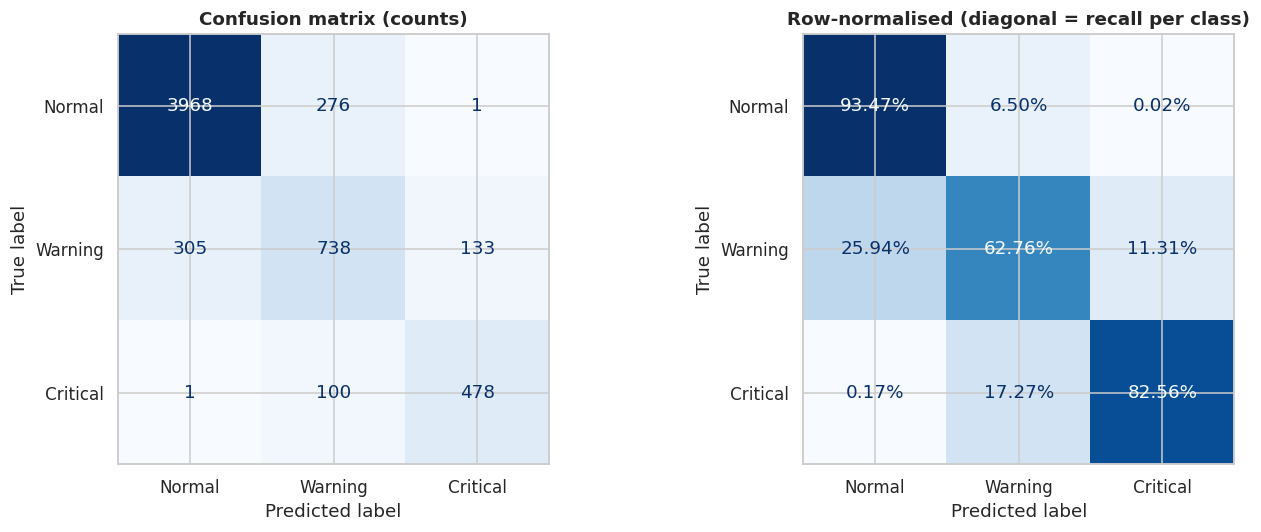

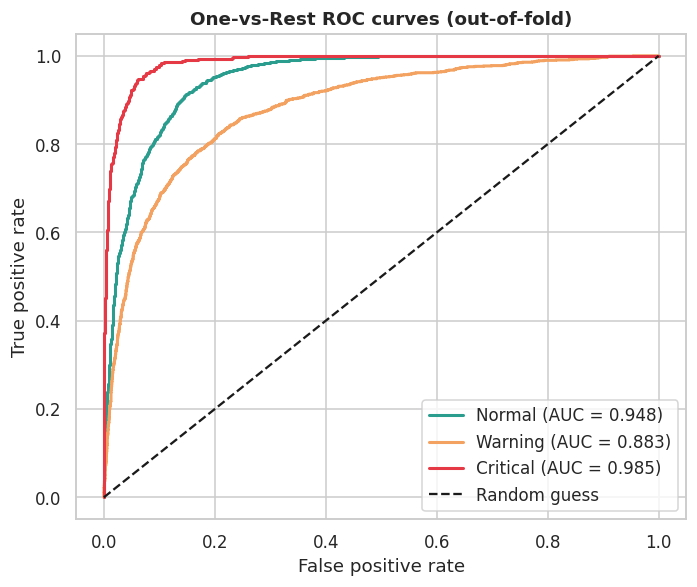

In [13]:
# ---- Out-of-fold probabilities: every machine is predicted by a model that NEVER saw it
P_cv    = cross_val_predict(pipe, X, y, cv=skf, method="predict_proba")
pred_cv = P_cv.argmax(axis=1)

print(classification_report(y, pred_cv, target_names=CLASSES, digits=3))

# ---- Confusion matrices (counts + row-normalised = per-class recall)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y, pred_cv, display_labels=CLASSES, cmap="Blues",
                                        ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y, pred_cv, display_labels=CLASSES, cmap="Blues",
                                        normalize="true", values_format=".2%", ax=axes[1], colorbar=False)
axes[1].set_title("Row-normalised (diagonal = recall per class)")
plt.tight_layout(); plt.show()

# ---- One-vs-rest ROC curves
Y_bin = label_binarize(y, classes=[0, 1, 2])
plt.figure(figsize=(6.5, 5.5))
for k, cls in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Y_bin[:, k], P_cv[:, k])
    plt.plot(fpr, tpr, color=COLORS[cls], linewidth=2, label=f"{cls} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("One-vs-Rest ROC curves (out-of-fold)"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 6.4 Cost-Sensitive Decision Making (Bayes minimum-risk rule)

Plain NB predicts $\arg\max_k P(k\mid\mathbf{x})$ — implicitly assuming **all mistakes cost the same**. In a factory they do not:

* Missing a **Critical** fault (→ "Normal") can destroy a machine and stop the line.
* A false alarm costs only an inspection.

Let $C_{jk}$ = cost of predicting class $k$ when the truth is $j$. The **expected risk** of action $k$ is

$$R(k\mid\mathbf{x})=\sum_{j}C_{jk}\,P(j\mid\mathbf{x})\qquad\Longrightarrow\qquad \hat y=\arg\min_k R(k\mid\mathbf{x})$$

This is **optimal** (Bayes decision theory) *provided the probabilities are well-calibrated* — which ties Section 4 and Section 6 together.

Cost matrix C[true, predicted]:


,pred Normal,pred Warning,pred Critical
true Normal,0,1,2
true Warning,10,0,3
true Critical,100,30,0


,total cost,avg cost / machine,Critical recall,Critical precision,accuracy,missed Criticals (→Normal)
decision rule,,,,,,
Standard argmax,6827.0,1.1378,0.8256,0.7810,0.8640,1
Cost-sensitive (min risk),4895.0,0.8158,0.9067,0.6774,0.7952,0


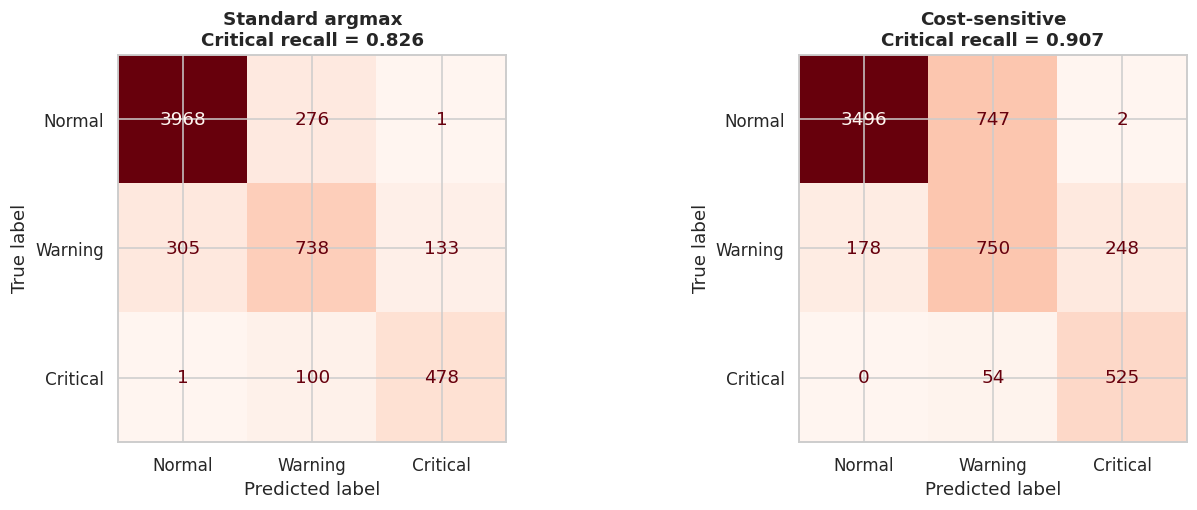

In [14]:
# ---- Cost matrix C[true, predicted]   (illustrative cost units — adjust with plant data!)
cost = pd.DataFrame([[  0,   1,   2],        # true Normal   -> unnecessary inspection / shutdown
                     [ 10,   0,   3],        # true Warning  -> missed early warning / over-reaction
                     [100,  30,   0]],       # true Critical -> catastrophic miss !
                    index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES])
print("Cost matrix C[true, predicted]:")
display(cost)
C = cost.to_numpy(dtype=float)

# ---- Decision rules
pred_argmax = P_cv.argmax(axis=1)               # standard NB: maximise probability
risk        = P_cv @ C                          # (n,K): expected cost of each possible action
pred_cost   = risk.argmin(axis=1)               # Bayes minimum-risk decision

def total_cost(y_true, y_pred):
    return C[y_true, y_pred].sum()

rows = []
for name, pred in [("Standard argmax", pred_argmax), ("Cost-sensitive (min risk)", pred_cost)]:
    rows.append({"decision rule": name,
                 "total cost":      total_cost(y, pred),
                 "avg cost / machine": total_cost(y, pred) / len(y),
                 "Critical recall":  recall_score(y, pred, labels=[2], average="macro"),
                 "Critical precision": precision_score(y, pred, labels=[2], average="macro", zero_division=0),
                 "accuracy":         accuracy_score(y, pred),
                 "missed Criticals (→Normal)": int(((y == 2) & (pred == 0)).sum())})
cost_table = pd.DataFrame(rows).set_index("decision rule")
display(cost_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (title, pred) in zip(axes, [("Standard argmax", pred_argmax), ("Cost-sensitive", pred_cost)]):
    ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=CLASSES, cmap="Reds",
                                            ax=ax, colorbar=False)
    ax.set_title(f"{title}\nCritical recall = {recall_score(y, pred, labels=[2], average='macro'):.3f}")
plt.tight_layout(); plt.show()

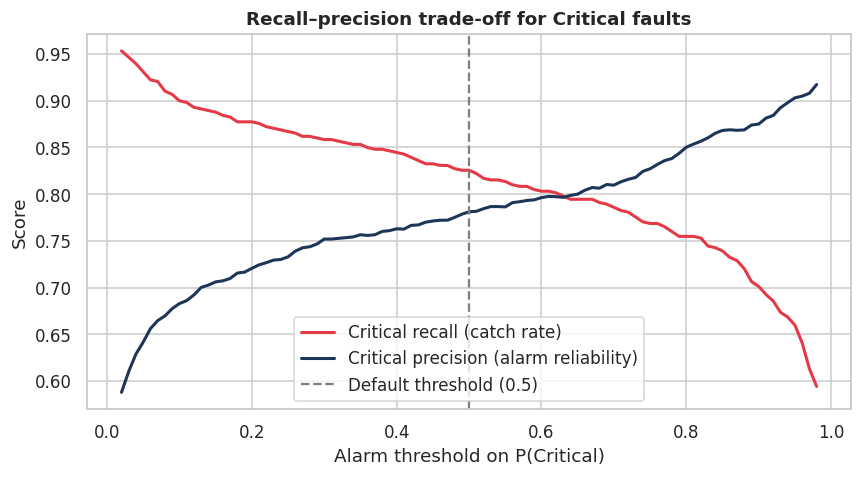

In [15]:
# ---- Threshold view: slide the "alarm if P(Critical) >= t" threshold and watch the trade-off
thr = np.linspace(0.02, 0.98, 97)
rec  = [recall_score(y == 2, P_cv[:, 2] >= t) for t in thr]
prec = [precision_score(y == 2, P_cv[:, 2] >= t, zero_division=0) for t in thr]

plt.figure(figsize=(8, 4.5))
plt.plot(thr, rec,  color="#e63946", linewidth=2, label="Critical recall (catch rate)")
plt.plot(thr, prec, color="#1d3557", linewidth=2, label="Critical precision (alarm reliability)")
plt.axvline(0.5, color="gray", linestyle="--", label="Default threshold (0.5)")
plt.xlabel("Alarm threshold on P(Critical)"); plt.ylabel("Score")
plt.title("Recall–precision trade-off for Critical faults")
plt.legend(); plt.tight_layout(); plt.show()

### 📌 How to interpret
* Lowering the alarm threshold (or using the minimum-risk rule) **raises Critical recall** at the price of **more false alarms** (lower precision). Because a Critical→Normal miss costs 100 units while a Normal→Critical false alarm costs 2 units, the cost-sensitive rule gives a **lower total cost** and higher Critical recall, even though raw accuracy **drops** (≈ 86 % → 80 %): we knowingly accept more false alarms.
* **Accuracy is the wrong headline metric** here; Critical recall + total cost are the business metrics.
* The cost matrix is a *business input*, not a statistical output — in practice, plant engineers set it.

---
## 7. Bonus — Save the Model & Diagnose a Single Machine

In [16]:
import joblib

# Final model: fit on the training split, evaluate once on the untouched test split
final_pipe = Pipeline([("scaler", StandardScaler()), ("gnb", GaussianNB())]).fit(X_train, y_train)
test_pred = final_pipe.predict(X_test)
print(f"Held-out TEST accuracy = {accuracy_score(y_test, test_pred):.4f} | "
      f"Critical recall = {recall_score(y_test, test_pred, labels=[2], average='macro'):.4f}")

joblib.dump(final_pipe, "sensor_fault_gnb_pipeline.joblib")      # one artifact = scaler + model

def diagnose_machine(vibration_amplitude_g, acoustic_decibels, bearing_temperature_c, motor_amperage,
                     model_path="sensor_fault_gnb_pipeline.joblib"):
    """Load the saved pipeline and score ONE machine; returns probabilities + the cost-optimal action."""
    model = joblib.load(model_path)
    x = np.array([[vibration_amplitude_g, acoustic_decibels, bearing_temperature_c, motor_amperage]])
    p = model.predict_proba(x)[0]
    return {"probabilities": dict(zip(CLASSES, p.round(4))),
            "argmax_decision": CLASSES[int(p.argmax())],
            "min_risk_decision": CLASSES[int((p @ C).argmin())]}

print(diagnose_machine(3.4, 83.0, 88.0, 24.5))     # a suspicious reading
print(diagnose_machine(0.7, 66.0, 58.0, 20.0))     # a healthy-looking reading

Held-out TEST accuracy = 0.8727 | Critical recall = 0.7793
{'probabilities': {'Normal': np.float64(0.0), 'Warning': np.float64(0.0001), 'Critical': np.float64(0.9999)}, 'argmax_decision': 'Critical', 'min_risk_decision': 'Critical'}
{'probabilities': {'Normal': np.float64(0.9998), 'Warning': np.float64(0.0002), 'Critical': np.float64(0.0)}, 'argmax_decision': 'Normal', 'min_risk_decision': 'Normal'}


---
## 🧠 Cheat-sheet: Key Takeaways & Viva Questions

| Question you may be asked | Short, confident answer |
|---|---|
| *Why "naive"?* | We assume sensors are independent **given the class**, so the joint likelihood factorises into a product of 1-D Gaussians. |
| *How does it train?* | Closed-form MLE: per-class mean, variance (ddof=0) and prior = class frequency. One pass, no gradient descent. |
| *Why log-probabilities?* | Products of small densities underflow; logs turn them into sums. Normalise with **log-sum-exp**. |
| *Is the assumption true here?* | No — hidden load/wear create within-class correlation (Section 3). NB still classifies well because only the **argmax** must be right, not the exact probabilities. |
| *Then what breaks?* | The **probabilities** become over-confident (double-counting correlated evidence) → fix with **Platt / isotonic calibration**. |
| *Does scaling matter?* | Not for Gaussian NB (scale-invariant — verified). It matters for KNN / logistic regression. |
| *Why not just accuracy?* | Classes are imbalanced and costs are asymmetric → use **Critical recall, ROC-AUC, Brier score and total cost**. |
| *What if a variance is 0?* | Variance smoothing ($\epsilon=10^{-9}\max\mathrm{Var}$) prevents division by zero. |
| *Decision boundary shape?* | **Quadratic** (class variances differ); it would be linear if all classes shared the same variance. |
| *How is it explainable?* | Posterior log-odds = prior + sum of per-sensor log-likelihood ratios → waterfall chart (Section 5.2). |